# 02 — The small model trades oil (local, via Ollama)

Notebook 01 proved the game with players that need no AI. This one puts **Qwen3 8B**, an open model running on this laptop, in the seat for the whole year, once with each of the three prompts (P1 the basic brief, P2 plus risk rules, P3 a structured brief). Same settings as September: temperature 0, seed 7, thinking off.

What to expect: about 15 seconds per day per prompt, so roughly an hour per prompt and three hours in all. Every answer is saved to disk the moment it arrives, so the notebook can be stopped at any time; running it again resumes where it stopped, and days already played come back instantly.

**How an AI player decides.** Each day the model reads one of the three prompts and that day's data, and writes its answer: a position (long, short or flat), its chance that oil closes higher tomorrow (`p_up`), a one-line thesis and a short reasoning. It never sets a stop: the game places the same disaster stop on every position (three ATRs from entry, at most 15%). Nothing in the code makes the choice for it. The decision is the model's own judgement, shaped by the prompt:

- **P1, the basic brief**: the rules only, no method. The model decides however it sees fit.
- **P2, plus risk rules**: the cost of changing position, flat when there is no clear view, 0.5 means no view; still no entry method.
- **P3, a structured brief**: read trend (20 and 60-day returns, distance to the 20 and 50-day averages), momentum (RSI, 5-day return) and location (distance to the 20-day high and low), weigh them yourself, and take a position when, on balance, the expected move beats the 0.04% round-trip cost; flat only with no view; keep a position while its reason holds.

**No threshold on `p_up`.** No level of `p_up` triggers a long or a short. The position and the chance of a rise are two separate answers, scored separately. A model may say 45% and stay flat, or 55% and go short because of a longer trend. This is deliberate: in September the chance was tied to a rule (no trade below 0.80) and both models simply wrote the smallest number the rule accepted.

**Every day is a new decision.** When a trade is open, the model is asked again each day, seeing its position, entry, the game's stop and unrealised P&L. Answering the same position keeps the trade; flat closes it at the next open; the opposite side reverses it. The disaster stop can also close it during any session.

**The reasoning is a window, not proof.** The written reasoning shows what the model says it checked. A language model's explanation does not always match how it reached its answer.

So the experiment does not test a trading rule. It tests whether the model's judgement, given only prices and one of these briefs, does better than doing nothing, holding oil, or a coin. (TimesFM is different: it forecasts, and a fixed rule written in advance turns its forecast into a position.)

For a quick look first, set `N_DAYS = 10` in the next cell. A quick look writes to separate folders (`data/results_quick/`, `data/summary_quick/`) and never touches the full-year results.

In [1]:
import sys, json, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from oilbench import rules
from oilbench.data import Market, load_or_download
from oilbench.engine import Book
from oilbench.prompt import MANDATES, build_payload, render_text
from oilbench.agents import Flat, BuyAndHold, LLMAgent
from oilbench.backends import OllamaBackend
from oilbench.replay import run, decision_dates, season_span, end_after, collect_saved
from oilbench.metrics import random_traders_cached, forecast_scores
from oilbench.live import LiveView
from oilbench.report import export_summary, load_summary, pnl_chart, luck_chart, trades_chart, calibration_chart, scoreboard, LABELS

MODEL = "qwen3:8b"
PROMPTS = ["P1", "P2", "P3"]
N_DAYS = None                     # None = the full year; 10 = a quick look
CACHE = ROOT / "data" / "llm_cache"                     # every answer, shared by full and quick runs
QUICK = "" if N_DAYS is None else "_quick"              # a quick look never overwrites the full year
RESULTS = ROOT / "data" / f"results{QUICK}"
SUMMARY_FOLDER = f"summary{QUICK}"
SUMMARY = ROOT / "data" / SUMMARY_FOLDER

md_ = Market.from_raw(load_or_download(ROOT / "data" / "wti_daily.csv"), adjust_rolls=rules.ADJUST_ROLLS)
END = rules.WINDOW_END if N_DAYS is None else end_after(md_, N_DAYS)
span = season_span(md_, rules.WINDOW_START, END)
dds = decision_dates(md_, rules.WINDOW_START, END)
print(f"{'QUICK LOOK: ' if QUICK else ''}{span['days']} decisions; first trade at the open of {span['first_fill']}, "
      f"last mark at the close of {span['last_mark']}; results go to {RESULTS.relative_to(ROOT)}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

250 decisions; first trade at the open of 2025-10-02, last mark at the close of 2026-09-30; results go to data/results


## 1. Is Ollama running, and is the model there?

In [2]:
backend = OllamaBackend(think=False)          # http://localhost:11434, thinking off, as in September
try:
    models = backend.list_models()
    print("Ollama is running. Models:", models)
except Exception as e:
    raise SystemExit(f"Ollama is not reachable ({e}). Start the Ollama app, then run this cell again.")
assert any(m.startswith(MODEL) for m in models), f"{MODEL} is not pulled: run `ollama pull {MODEL}` in Terminal"
print(f"✓ {MODEL} is available")

Ollama is running. Models: ['qwen3:8b']
✓ qwen3:8b is available


## 2. One day, by hand

Send one day to the model with prompt P1 and look at its answer before playing the year. The first call loads the model into memory, so it is slower than the rest.

In [3]:
t = dds[0]
payload = build_payload(md_.asof(t), Book().snapshot(float(md_.bar(t)["close"])))
agent = LLMAgent("qwen3-8b_P1", backend, MODEL, prompt="P1", cache_dir=CACHE)
t0 = time.time()
d = agent.decide(payload)
r = agent.records[-1]
print(f"{t.date()}  WTI close {payload['price']}")
print(f"answer in {time.time() - t0:.1f}s ({'from the saved answers' if r.cached else 'live'}), "
      f"{r.prompt_tokens} prompt tokens, {r.completion_tokens} answer tokens, repaired: {r.repaired}\n")
print("POSITION :", d.position)
print("P_UP     :", d.p_up)
print("THESIS   :", d.thesis)
print("REASONING:", d.reasoning)

2025-10-01  WTI close 61.78
answer in 0.0s (from the saved answers), 2876 prompt tokens, 72 answer tokens, repaired: False

POSITION : short
P_UP     : 0.35
THESIS   : Shorting due to bearish trend and oversold conditions.
REASONING: The price is below the 20-day SMA and RSI is neutral. A short position is likely to capitalize on the downward trend.


## 3. Timing on a fresh day

Saved answers come back instantly, so timing needs a day that has not been asked yet. This finds one, asks it, and estimates the full year.

In [4]:
timing = LLMAgent("qwen3-8b_P1", backend, MODEL, prompt="P1", cache_dir=CACHE)
for t_fresh in dds[::-1]:
    p = build_payload(md_.asof(t_fresh), Book().snapshot(float(md_.bar(t_fresh)["close"])))
    if not (timing.cache_dir / f"{timing._key(render_text(p))}.json").exists():
        break
timing.decide(p)
sec = timing.records[-1].latency_s
print(f"{t_fresh.date()}: {sec:.1f}s for a fresh answer")
n_year = season_span(md_)["days"]
print(f"≈ {sec * n_year / 60:.0f} min per prompt for the full year, ≈ {sec * n_year * len(PROMPTS) / 3600:.1f} h for all {len(PROMPTS)} prompts")

2026-09-28: 12.1s for a fresh answer
≈ 50 min per prompt for the full year, ≈ 2.5 h for all 3 prompts


## 4. Play the year, one prompt per cell (long — leave each running)

One cell per prompt, so each can be run (or rerun) on its own: the results are saved to `data/results/` as each prompt finishes, and section 5 reads all three back from there. A prompt already played comes back from the saved answers in seconds.

One line per day: the date, the WTI close, the position the account holds after that day's decision, the game's disaster stop in force, the model's chance that oil closes higher tomorrow, the running P&L, and its one-line thesis. Notes flag a disaster stop hit or an answer that could not be used. A progress line every 25 days gives the time left.

Safe to interrupt (Kernel → Interrupt). If Ollama stops answering, the run stops with a message rather than counting the missing days as decisions. Either way, running the cell again resumes from the saved answers.

In [5]:
results = {}

def play(k, end=END, save=True):
    """Play one prompt from the start of the window to `end`; save it unless it is a quick look."""
    name = f"qwen3-8b_{k}"
    agent = LLMAgent(name, backend, MODEL, prompt=k, cache_dir=CACHE)
    print(f"==== {name}: {LABELS.get(name, name)} ====")
    view = LiveView()
    res = run(md_, [agent], rules.WINDOW_START, end, on_day=view.day, on_decision=view.decision,
              log_dir=(RESULTS / name) if save else None)[name]
    live = [x.latency_s for x in agent.records if not x.cached]
    tr, log = res["trades"], res["log"]
    print(f"done: {len(agent.records)} answers ({sum(x.cached for x in agent.records)} saved earlier), "
          f"{sum(x.repaired for x in agent.records)} repaired, {sum(bool(x.invalid) for x in agent.records)} invalid, "
          f"{np.mean(live) if live else 0:.1f}s per live answer")
    print(f"days long / short / flat: {(log['held'] == 'long').sum()} / {(log['held'] == 'short').sum()} / {(log['held'] == 'flat').sum()}; "
          f"trades {len(tr)}; distinct p_up values {log['p_up'].round(2).nunique()}; final P&L {res['balance'].iloc[-1] - 10_000:+,.0f}")
    return res

### 4a. Prompt 1, the basic brief

In [6]:
results["qwen3-8b_P1"] = play("P1")

==== qwen3-8b_P1: Qwen3 8B, Prompt 1 ====
2025-10-01  WTI  61.78  qwen3-8b_P1    SHORT  stop   66.56  p_up 0.35  P&L    +208  Shorting due to bearish trend and oversold conditions.
2025-10-02  WTI  60.48  qwen3-8b_P1    FLAT                 p_up 0.65  P&L    +171  Price may reverse due to oversold conditions and proximity to the stop
2025-10-03  WTI  60.88  qwen3-8b_P1    SHORT  stop   65.83  p_up 0.35  P&L     +77  Shorting near 20-day low with weak momentum and high volatility.
2025-10-06  WTI  61.69  qwen3-8b_P1    FLAT                 p_up 0.45  P&L     +69  Price may reverse due to overbought RSI and proximity to the stop.
2025-10-07  WTI  61.73  qwen3-8b_P1    SHORT  stop   66.69  p_up 0.35  P&L     -15  Shorting near 20-day low with high volatility and weak momentum.
2025-10-08  WTI  62.55  qwen3-8b_P1    FLAT                 p_up 0.45  P&L     +22  Price may reverse due to overbought RSI and proximity to the stop.
2025-10-09  WTI  61.51  qwen3-8b_P1    SHORT  stop   66.25  p_up

### 4b. Prompt 2, plus risk rules

In [7]:
results["qwen3-8b_P2"] = play("P2")

==== qwen3-8b_P2: Qwen3 8B, Prompt 2 ====
2025-10-01  WTI  61.78  qwen3-8b_P2    FLAT                 p_up 0.45  P&L      +0  Price is consolidating; no clear directional bias.
2025-10-02  WTI  60.48  qwen3-8b_P2    FLAT                 p_up 0.40  P&L      +0  Weak trend with no clear direction; wait for stronger signals.
2025-10-03  WTI  60.88  qwen3-8b_P2    SHORT  stop   65.83  p_up 0.30  P&L     -92  Price likely to retest lower due to weak momentum and high volatility.
2025-10-06  WTI  61.69  qwen3-8b_P2    FLAT                 p_up 0.45  P&L    -100  Price may reverse due to overbought RSI and proximity to the stop.
2025-10-07  WTI  61.73  qwen3-8b_P2    SHORT  stop   66.69  p_up 0.30  P&L    -182  Shorting due to weak momentum and overbought RSI, expecting a pullback
2025-10-08  WTI  62.55  qwen3-8b_P2    FLAT                 p_up 0.30  P&L    -146  Price may reverse due to overbought RSI and proximity to the stop.
2025-10-09  WTI  61.51  qwen3-8b_P2    FLAT                 p_up

### 4c. Prompt 3: a quick look first (20 days, not saved)

Look at 20 days of P3 before committing an hour: does it take positions, does it hold them, does its chance of a rise vary? These answers are saved, so the full year in 4d reuses them.

In [8]:
quick_p3 = play("P3", end=end_after(md_, 20), save=False)
for _, r in quick_p3["log"].head(5).iterrows():
    print(f"{r['decision_date']}  {r['wanted'].upper():<5} p_up {r['p_up']}  {r['reasoning']}")

==== qwen3-8b_P3: Qwen3 8B, Prompt 3 ====
2025-10-01  WTI  61.78  qwen3-8b_P3    FLAT                 p_up 0.50  P&L      +0  No clear trend or momentum; price is below key support.
2025-10-02  WTI  60.48  qwen3-8b_P3    SHORT  stop   65.44  p_up 0.45  P&L     -32  Bearish trend with weak momentum, shorting near 20-day low.
2025-10-03  WTI  60.88  qwen3-8b_P3    SHORT  stop   65.44  p_up 0.45  P&L    -165  Short WTI crude oil due to weak trend, low momentum, and proximity to 
2025-10-06  WTI  61.69  qwen3-8b_P3    FLAT                 p_up 0.55  P&L    -174  Short position under pressure; potential reversal expected.
2025-10-07  WTI  61.73  qwen3-8b_P3    SHORT  stop   66.69  p_up 0.35  P&L    -255  Short WTI due to bearish trend and proximity to 20-day low.
2025-10-08  WTI  62.55  qwen3-8b_P3    SHORT  stop   66.69  p_up 0.45  P&L     -90  Short WTI due to negative trend and momentum, price near 20-day low.
2025-10-09  WTI  61.51  qwen3-8b_P3    FLAT                 p_up 0.65  P&L    

### 4d. Prompt 3, the full year

In [9]:
results["qwen3-8b_P3"] = play("P3")

==== qwen3-8b_P3: Qwen3 8B, Prompt 3 ====
2025-10-01  WTI  61.78  qwen3-8b_P3    FLAT                 p_up 0.50  P&L      +0  No clear trend or momentum; price is below key support.
2025-10-02  WTI  60.48  qwen3-8b_P3    SHORT  stop   65.44  p_up 0.45  P&L     -32  Bearish trend with weak momentum, shorting near 20-day low.
2025-10-03  WTI  60.88  qwen3-8b_P3    SHORT  stop   65.44  p_up 0.45  P&L    -165  Short WTI crude oil due to weak trend, low momentum, and proximity to 
2025-10-06  WTI  61.69  qwen3-8b_P3    FLAT                 p_up 0.55  P&L    -174  Short position under pressure; potential reversal expected.
2025-10-07  WTI  61.73  qwen3-8b_P3    SHORT  stop   66.69  p_up 0.35  P&L    -255  Short WTI due to bearish trend and proximity to 20-day low.
2025-10-08  WTI  62.55  qwen3-8b_P3    SHORT  stop   66.69  p_up 0.45  P&L     -90  Short WTI due to negative trend and momentum, price near 20-day low.
2025-10-09  WTI  61.51  qwen3-8b_P3    FLAT                 p_up 0.65  P&L    

## 5. The simple players, the random traders, and the summary

Do nothing and hold oil play the same days. The 1,000 random traders are played once for exactly this window and saved under a file name that carries it (notebook 01 already did this for the full year). Every player already played in notebooks 03 and 04 is read back from the saved results too, and everything is written to `data/summary/` (or `data/summary_quick/`), the small folder the story notebook reads.

In [10]:
base = run(md_, [Flat(), BuyAndHold()], rules.WINDOW_START, END)
null = random_traders_cached(md_, ROOT / "data" / "results", rules.WINDOW_START, END,
                             on_batch=lambda done, n, s: print(f"\r  random traders {done}/{n}  {s:.0f}s", end=""))
print("\nrandom traders for the window", null["window"].iloc[0])
saved = collect_saved(RESULTS)                                  # every player saved so far (02, 03, 04)
missing = [f"qwen3-8b_{k}" for k in PROMPTS if f"qwen3-8b_{k}" not in saved]
assert not missing, f"not played yet: {missing} (run its cell in section 4)"
results = {f"qwen3-8b_{k}": saved[f"qwen3-8b_{k}"] for k in PROMPTS}   # the three prompts, read back from disk
everything = {**saved, **base}
assert all(len(r["log"]) == span["days"] for r in everything.values()), "players must cover the same days (rerun any that do not)"
export_summary(everything, null, SUMMARY, {**span, "model": MODEL, "quick_look": bool(QUICK),
                                           "run_date": str(pd.Timestamp.today().date())})
S = load_summary(ROOT, SUMMARY_FOLDER)
SMALL = [LABELS[f"qwen3-8b_{k}"] for k in PROMPTS]
BASE = ["Do nothing (cash)", "Hold oil all year"]
print("summary written to", SUMMARY)


random traders for the window 2025-10-01_2026-09-29_250d_n1000
summary written to ./data/summary


## 6. Results

### The scoreboard and the P&L through the year

In [11]:
scoreboard(S, SMALL + BASE)

,"P&L, USD","Return on $10,000",Beats random traders (in 100),Trades,Winning trades,Stopped out,Days long / short / flat
player,,,,,,,
"Qwen3 8B, Prompt 1",-731,-7.3%,56,109,43%,0,82 / 84 / 84
"Qwen3 8B, Prompt 2","-3,566",-35.7%,27,97,47%,3,56 / 64 / 130
"Qwen3 8B, Prompt 3","+1,140",+11.4%,70,30,37%,2,124 / 92 / 34
Do nothing (cash),+0,+0.0%,61,0,-,0,0 / 0 / 250
Hold oil all year,"+4,630",+46.3%,86,1,100%,0,250 / 0 / 0


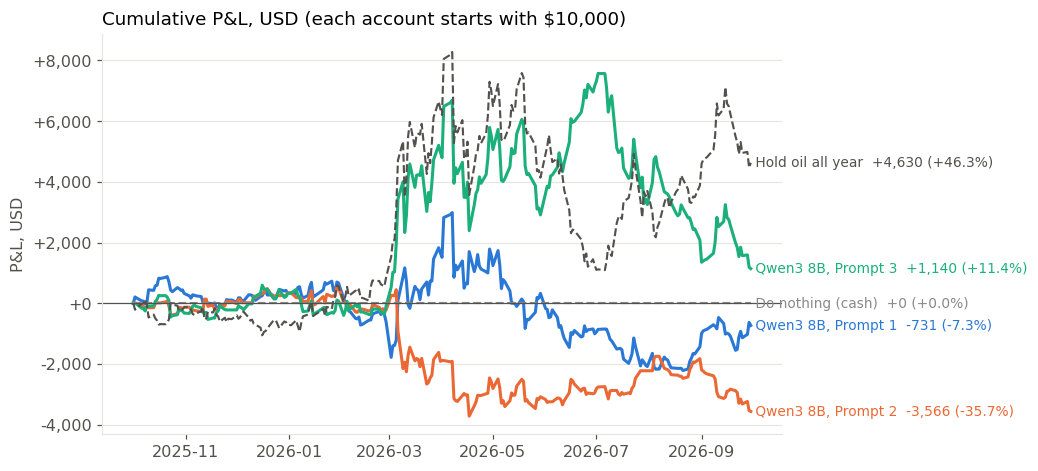

In [12]:
pnl_chart(S, SMALL + BASE);

### Skill or luck? Where each prompt lands among the 1,000 random traders

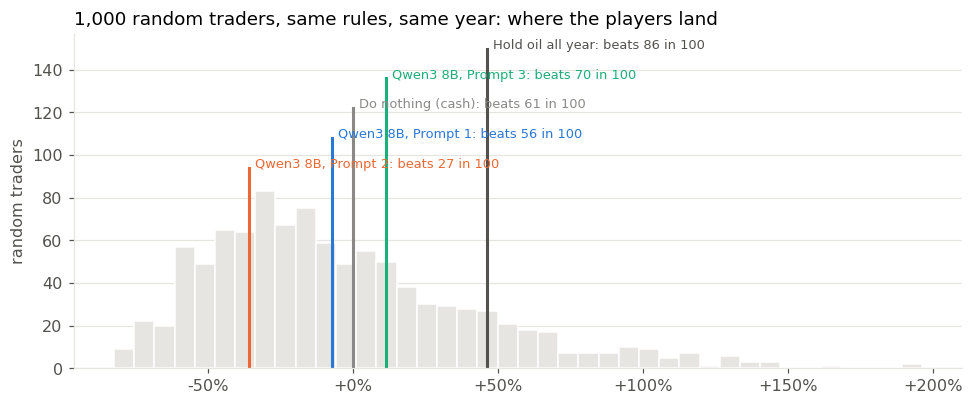

In [13]:
luck_chart(S, SMALL + BASE);

### The trades behind each result

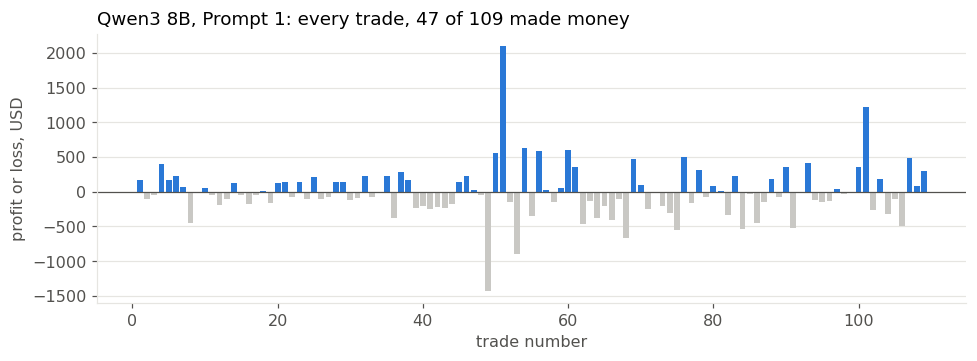

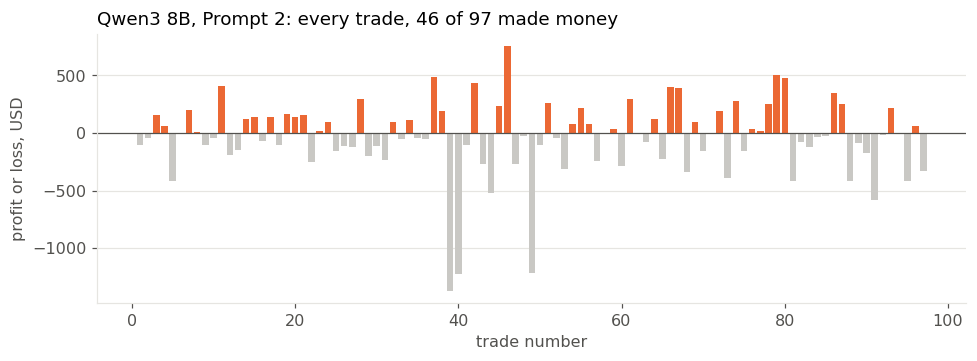

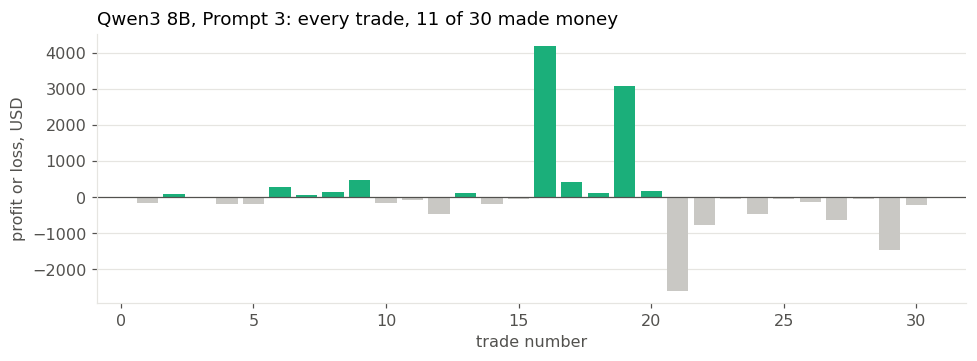

In [14]:
for p in SMALL:
    if not S.trades.empty and (S.trades["player"] == p).any():
        trades_chart(S, p); plt.show()

### How each prompt behaved

Days long, short and flat; how many times the model itself asked for a different position (starting from flat); how many trades ended at the disaster stop; and how many answers could not be used.

In [15]:
rows = []
for k in PROMPTS:
    name = f"qwen3-8b_{k}"; log = results[name]["log"]; tr = results[name]["trades"]
    before = log["held"].shift(fill_value="flat")          # the position going into each decision
    rows.append({"prompt": k, "days long": int((log["held"] == "long").sum()), "days short": int((log["held"] == "short").sum()),
                 "days flat": int((log["held"] == "flat").sum()), "position changes asked": int((log["wanted"] != before).sum()),
                 "trades": len(tr), "stopped out": int((tr["reason"] == "stop").sum()) if len(tr) else 0,
                 "unusable answers": int((log["invalid"] != "").sum())})
pd.DataFrame(rows).set_index("prompt")

,days long,days short,days flat,position changes asked,trades,stopped out,unusable answers
prompt,,,,,,,
P1,82,84,84,192,109,0,0
P2,56,64,130,190,97,3,0
P3,124,92,34,54,30,2,0


### Did its daily chance of a rise mean anything?

Each day the model stated the chance that oil closes higher tomorrow, with no rule attached. A Brier score below 0.25 (always saying 50%) and a skill above zero would mean the numbers carry information.

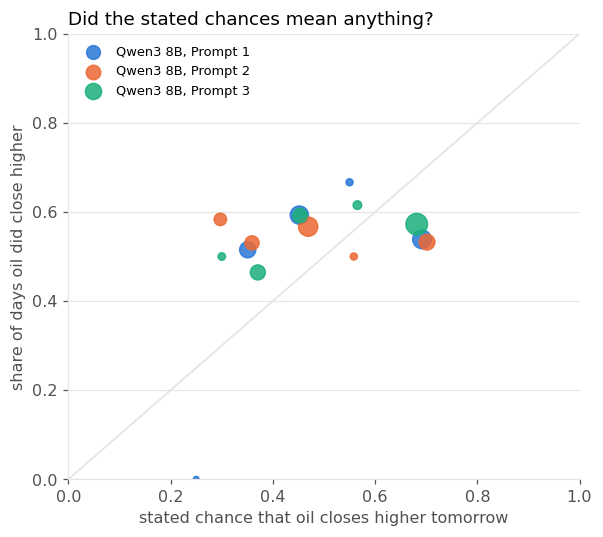

In [16]:
calibration_chart(S, SMALL);

In [17]:
fs = pd.DataFrame({k: forecast_scores(results[f"qwen3-8b_{k}"]["log"]) for k in PROMPTS}).T
fs[["n_forecasts", "n_missing", "mean_p_up", "distinct_values", "hit_rate", "share_up_days", "brier", "brier_no_view", "brier_skill"]].round(3)

,n_forecasts,n_missing,mean_p_up,distinct_values,hit_rate,share_up_days,brier,brier_no_view,brier_skill
P1,250.0,0.0,0.514,9.0,0.486,0.552,0.267,0.25,-0.070
P2,250.0,0.0,0.483,11.0,0.465,0.552,0.273,0.25,-0.093
P3,250.0,0.0,0.549,9.0,0.530,0.552,0.259,0.25,-0.036


### A few days in the model's own words

The first six days on which the model asked for a different position (prompt P3), with what happened to the request.

In [18]:
log = results["qwen3-8b_P3"]["log"]
before = log["held"].shift(fill_value="flat")
asked = log[log["wanted"] != before].head(6)
for _, r in asked.iterrows():
    outcome = ("closed the position" if r["wanted"] == "flat" and r["held"] == "flat" else
               "opened" if r["held"] == r["wanted"] else
               "disaster stop hit the same session" if r["closed_trades"] else "not filled")
    print(f"{r['decision_date']}  WTI {r['close']:.2f}  asked {r['wanted'].upper()} ({outcome})  p_up {r['p_up']}\n   {r['reasoning']}\n")

2025-10-02  WTI 60.48  asked SHORT (opened)  p_up 0.45
   The price is below the 20-day SMA, with weak momentum and low volatility. The trend is bearish, but the location is near the 20-day low, suggesting potential for a rebound.

2025-10-06  WTI 61.69  asked FLAT (closed the position)  p_up 0.55
   The price is below the 20-day SMA, RSI is neutral, and the trend is weak. The position is short, but the recent pullback suggests a potential reversal.

2025-10-07  WTI 61.73  asked SHORT (opened)  p_up 0.35000000000000003
   The price is near the 20-day low, with weak momentum and negative returns. A short is justified due to the bearish trend and proximity to support.

2025-10-09  WTI 61.51  asked FLAT (closed the position)  p_up 0.65
   The price is near the 20-day low, with weak momentum and a negative trend. The short position is under pressure, and the stop is approaching. The view leans toward a potential reversal.

2025-10-13  WTI 59.49  asked SHORT (opened)  p_up 0.350000000000000

## 7. What this run found

**Qwen3 8B, on this laptop, played the test year (1 October 2025 to 30 September 2026) under the final rules: a disaster stop of three ATRs, at most 15%, and 0.02% per fill.** It ran once with each prompt, at temperature 0 with seed 7. All 750 answers were usable and none needed repair.

| Prompt | P&L | Beats random traders (in 100) | Trades | Days long / short / flat | Brier skill |
|---|---|---|---|---|---|
| P1, the basic brief | −$731 (−7.3%) | 56 | 109 | 82 / 84 / 84 | −0.070 |
| P2, plus risk rules | −$3,566 (−35.7%) | 27 | 97 | 56 / 64 / 130 | −0.093 |
| P3, a structured brief | **+$1,140 (+11.4%)** | 70 | 30 | 124 / 92 / 34 | −0.036 |
| Do nothing | $0 | 61 | 0 | 0 / 0 / 250 | |
| Hold oil all year | +$4,630 (+46.3%) | 86 | 1 | 250 / 0 / 0 | |

- **The brief moved the result more than anything else.** It was the same model, the same prices and the same rules each time, and the result ranged from −35.7% to +11.4% depending on the wording of the brief. **No brief beat simply holding oil.**
- **P1 traded constantly.** It made 109 trades and asked to change position 192 times. Its longs made +$1,603; its shorts lost −$2,334 in a year when oil rose 46%. Fees came to $421.
- **P2's risk rules made it worse.** It flipped between flat and long, sat out many of the big up days, and lost on both longs (−$1,266) and shorts (−$2,300).
- **P3 traded like a trend follower:** long from February, short from June. **Two trades made all its money:** a long from 19 February to 3 June ($65 to $93, +$4,185) and a short from 12 June to 2 July ($87 to $68, +$3,073). Its other 28 trades lost −$6,118 between them, and only 37% of its trades won. It peaked at +$7,573 on 2 July, then gave back $6,400 in the choppy months that followed. Two of those shorts were closed by the disaster stop (−$2,598 and −$1,466).
- **No stated chance of a rise meant anything.** Every prompt scored worse than always saying 50%.
- **Its reasoning reads plausibly, but it is not reliable.** For example, it wrote "price near 20-day low, RSI overbought" (2 June), and on another day "suggesting potential for a rebound" before going short.

**Caveats.** Each prompt is one run at temperature 0, so each result is a single path, not an average. P3's +11.4% rests almost entirely on two trades.

Next: `03_large_model.ipynb`, the same year with GPT-5.1.